# 2 · PCA, K-means y reconocimiento de huellas
### De una nube de puntos a una decisión de acceso

**Objetivo:** comprender la estandarización, PCA, agrupamiento, selección de características, umbral y ampliación con Anguli. Incluye el **PCA actualizado del modelo combinado**.

Conviene separar tres preguntas: ¿cómo se distribuyen los datos?, ¿qué grupos encuentra el algoritmo?, ¿cuándo aceptamos una consulta? PCA, K-means y el umbral responden preguntas distintas.

Los nuevos gráficos utilizan 295 vectores de desarrollo: 180 autorizados de entrenamiento y 115 de validación. Solo los 180 de entrenamiento ajustan PCA. Los parámetros del reconocedor permanecen fijos: 36 columnas, escalado, tres centroides, correspondencia y umbral. No se abre la prueba final ni se reentrena K-means.

In [9]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Ejecutar con la carpeta de estos notebooks como directorio de trabajo.
DATOS = Path("datos")
FIGURAS = Path("figuras")
plt.rcParams.update({"figure.figsize": (12, 5), "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "figure.dpi": 110})
COLORES = {"A01": "#2563EB", "A02": "#0D9488", "A03": "#9333EA",
           "I01": "#DC2626", "I02": "#EA580C"}

from sklearn.decomposition import PCA
paquete = np.load(DATOS / "huellas_desarrollo.npz")
meta = pd.read_csv(DATOS / "huellas_catalogo.csv")
X = paquete["X"]
train = meta["particion"].eq("entrenamiento").to_numpy()
val = ~train
Z = (X[:, paquete["indices"]] - paquete["media"]) / paquete["escala"]
centros = paquete["centroides"]
correspondencia = json.loads((DATOS / "correspondencia.json").read_text())
tau = json.loads((DATOS / "pca_resumen.json").read_text())["umbral"]

## Estandarizar: comparar números en unidades semejantes

Una característica que varía entre 0 y 1000 puede dominar una distancia sobre otra entre 0 y 1, aunque no sea más útil. Para cada columna restamos su media y dividimos por su desviación de entrenamiento:

$$\boxed{z_j=\frac{x_j-\mu_{j,train}}{\sigma_{j,train}}}$$

Un valor de 30, con media 20 y desviación 5, se convierte en 2: dos desviaciones por encima del promedio. Se usan las mismas medias y escalas para todas las clases y consultas. No se escala una huella según su identidad, que todavía no conocemos.

En el proyecto el escalado usa desviación poblacional (ddof=0). Para describir dispersión entre muestras en tablas se puede usar la muestral (ddof=1); son convenciones para propósitos distintos. Una columna constante requiere un tratamiento explícito y no se divide por cero.

Aquí cargamos el escalado ya guardado. Estandarizar no vuelve útiles a todas las columnas ni borra diferencias entre clases; evita que las unidades determinen por sí solas las distancias.

## PCA: construir nuevos ejes

PCA significa análisis de componentes principales. Cada componente combina las características de entrada:

$$PC_r=a_{r1}z_1+\cdots+a_{rp}z_p.$$

PC1 es la dirección de mayor variación; PC2 recoge la mayor variación restante en una dirección perpendicular. El número indica el orden de varianza, no el número de una columna original. Los coeficientes se aprenden del conjunto, y después se aplican a todas las muestras.

PCA trabaja con datos centrados. La implementación guarda también su media, aunque el escalado de entrenamiento ya produzca medias prácticamente nulas. Matemáticamente se buscan direcciones de la matriz de covarianza; sus autovalores expresan la varianza de esas direcciones. La implementación por SVD obtiene esa descomposición de manera numérica.

Los pesos de una componente tienen norma uno. Sin esa condición podríamos multiplicarlos por un número enorme y aumentar artificialmente la varianza. La perpendicularidad evita contar repetidamente la misma dirección.

PCA no recibe las etiquetas de identidad. Cambiar colores del gráfico no cambia sus coordenadas. Cambiar las columnas, el escalado o el entrenamiento sí puede cambiarlas. Invertir el signo de un eje produce un reflejo equivalente, no otro resultado de reconocimiento.

### Varianza explicada

$$\boxed{\text{Fracción de varianza de PC}_r=\frac{\lambda_r}{\sum_j\lambda_j}}$$

La suma acumulada dice cuánta variación conserva una proyección. No es porcentaje de aciertos. El 5 % que quede fuera puede contener ruido o diferencias útiles: PCA no sabe cuál es cuál.

Usar PCA para dibujar no equivale a clasificar con dos componentes. Nuestro K-means actual trabaja en 36 características; este plano es una vista de ese espacio.

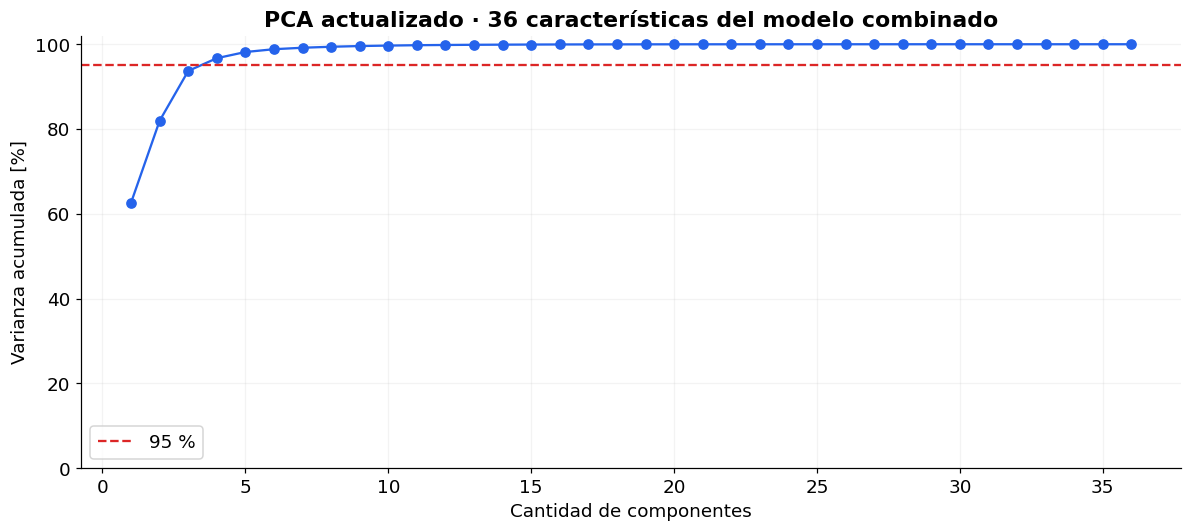

,Componente,Varianza [%],Acumulada [%]
0,PC1,62.64,62.64
1,PC2,19.32,81.96
2,PC3,11.75,93.71
3,PC4,3.00,96.71


In [10]:
# Único ajuste nuevo: PCA de visualización, exclusivamente con entrenamiento.
pca = PCA(svd_solver="full")
pca.fit(Z[train])
P = pca.transform(Z)
C = pca.transform(centros)
fracciones = pca.explained_variance_ratio_
acumulada = fracciones.cumsum()
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(np.arange(1, len(fracciones)+1), acumulada*100, "o-", color="#2563EB")
ax.axhline(95, color="#DC2626", ls="--", label="95 %")
ax.set(xlabel="Cantidad de componentes", ylabel="Varianza acumulada [%]",
       title="PCA actualizado · 36 características del modelo combinado", ylim=(0, 102))
ax.legend(); ax.grid(alpha=0.15); plt.tight_layout(); plt.show()
display(pd.DataFrame({"Componente": ["PC1", "PC2", "PC3", "PC4"],
    "Varianza [%]": 100*fracciones[:4], "Acumulada [%]": 100*acumulada[:4]}).round(2))

**Resultado nuevo:** PC1 explica aproximadamente 62,64 %, PC2 19,32 % y PC3 11,75 %. PC1–PC2 conserva **81,96 %**; las primeras cuatro alcanzan el 95 %. Estos porcentajes corresponden al espacio seleccionado actual, no al de 144 ni al anterior de 72 columnas.

El cálculo reproduce las medias guardadas del entrenamiento combinado al reconstruir sus vectores. Esa comprobación se realizó durante la preparación del material, fuera del notebook. La procedencia técnica se conserva en `datos/procedencia.json`.

## K-means: formar grupos compactos

Clusterizar significa agrupar por semejanza. K-means recibe vectores, no identidades, y busca k grupos. En nuestro caso k=3 por las tres identidades autorizadas exigidas.

Comienza con tres centros. Asigna cada punto al más cercano y recalcula cada centro como el promedio de sus puntos. Repite hasta estabilizarse o cumplir el criterio de parada. Un centroide es un vector promedio, no necesariamente una imagen real.

$$\boxed{d(\mathbf z,\mathbf c)=\sqrt{\sum_{j=1}^{p}(z_j-c_j)^2}}$$

$$J=\sum_i\|\mathbf z_i-\mathbf c_{g(i)}\|^2.$$

La distancia euclidiana determina cercanía; K-means minimiza la suma de distancias al cuadrado. No usa distancia entre píxeles ni porcentaje de parecido. Supone grupos que pueden representarse razonablemente mediante centros y distancias; formas muy alargadas o complejas pueden no encajar bien.

Usamos inicialización k-means++, 20 inicializaciones, máximo 300 iteraciones, tolerancia 0,0001 y semilla 20261022. Las inicializaciones reducen dependencia de un único comienzo, pero no garantizan el óptimo global. La semilla permite reproducir esa parte aleatoria; no se elige una semilla porque dé mejor validación.

Los intrusos no se incluyen para aprender los tres centroides autorizados. Después de agrupar, relacionamos los números arbitrarios de grupo con las identidades usando entrenamiento. Esa correspondencia se guarda. En el modelo actual: grupo 2 → A01, grupo 0 → A02 y grupo 1 → A03.

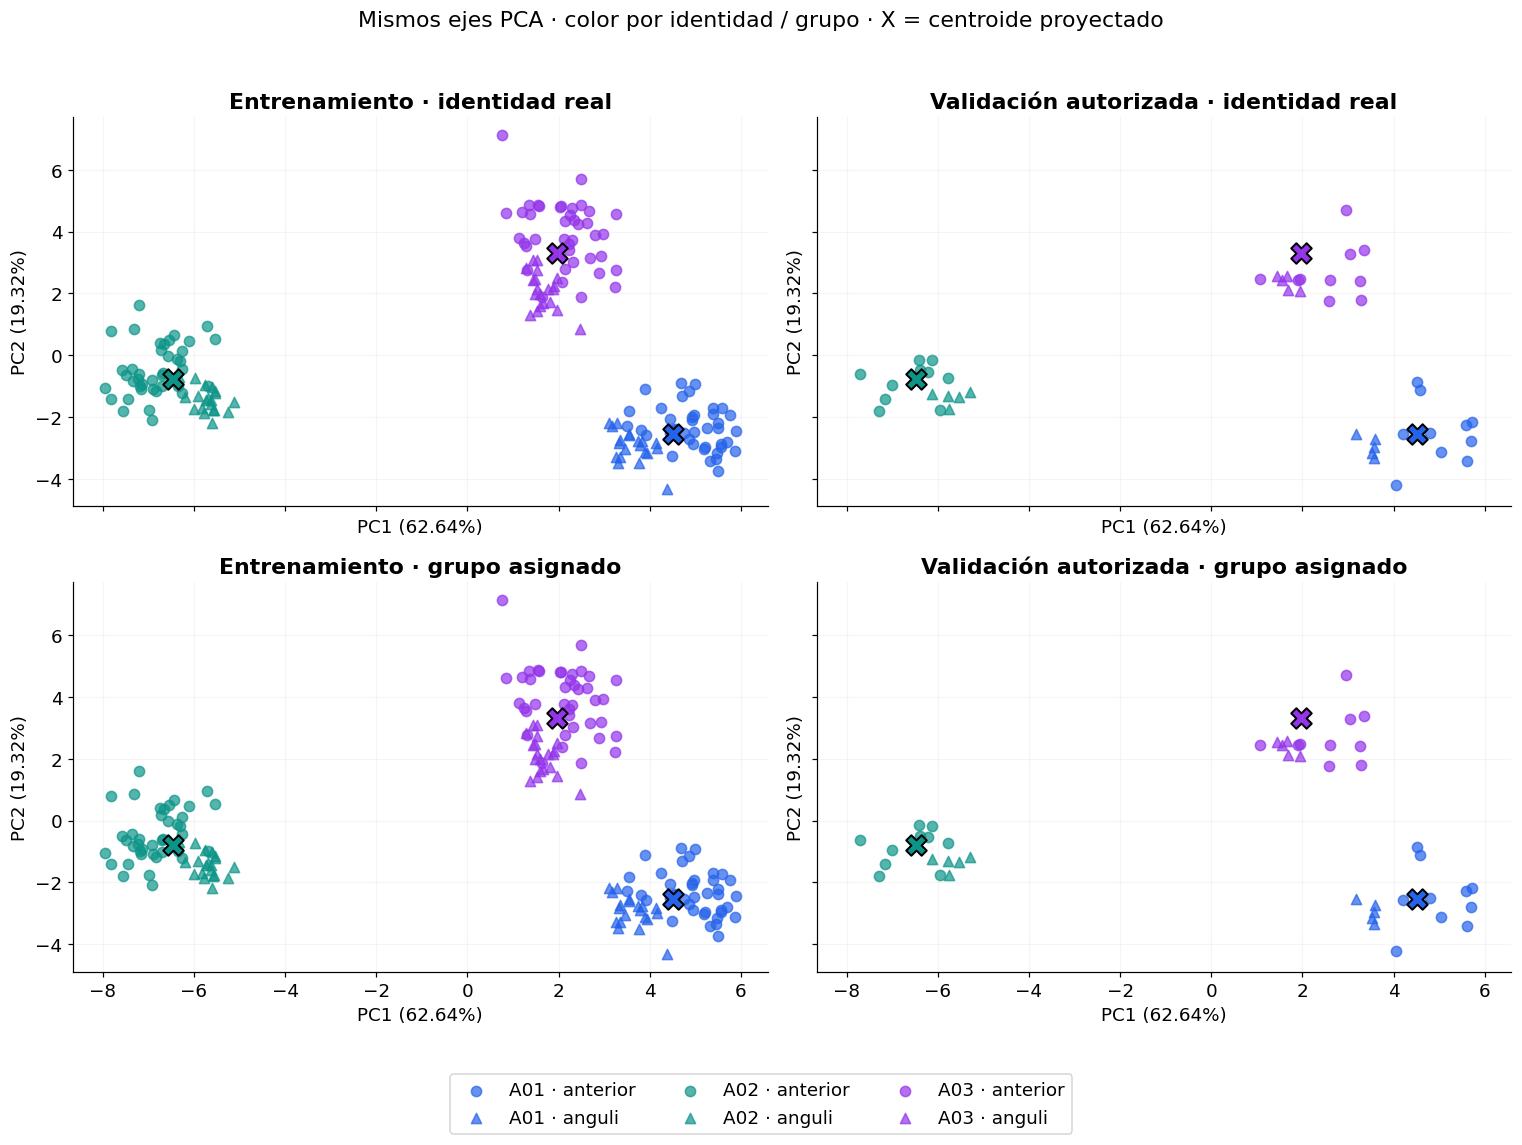

In [11]:
distancias = np.linalg.norm(Z[:, None, :] - centros[None, :, :], axis=2)
grupos = distancias.argmin(axis=1)
identidades = np.array([correspondencia[str(g)] for g in grupos])
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
for col, (mascara, titulo) in enumerate([(train, "Entrenamiento"),
                      (val & meta["grupo"].eq("autorizado").to_numpy(), "Validación autorizada")]):
    for fila in range(2):
        ax = axes[fila, col]
        etiquetas = meta["identidad"].to_numpy() if fila == 0 else identidades
        for identidad in ["A01", "A02", "A03"]:
            for fuente, marcador in [("anterior", "o"), ("anguli", "^")]:
                m = mascara & (etiquetas == identidad) & meta["fuente"].eq(fuente).to_numpy()
                ax.scatter(P[m, 0], P[m, 1], color=COLORES[identidad], marker=marcador,
                           s=45, alpha=0.7, label=f"{identidad} · {fuente}")
        for g, c in enumerate(C):
            ax.scatter(c[0], c[1], marker="X", s=180, c=COLORES[correspondencia[str(g)]],
                       edgecolors="black", linewidth=1.3)
        ax.set_title(titulo + (" · identidad real" if fila == 0 else " · grupo asignado"))
        ax.set_xlabel(f"PC1 ({fracciones[0]:.2%})"); ax.set_ylabel(f"PC2 ({fracciones[1]:.2%})")
        ax.grid(alpha=0.12)
handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Mismos ejes PCA · color por identidad / grupo · X = centroide proyectado", y=1.02)
plt.tight_layout(rect=(0,0.08,1,1)); plt.show()

**Cómo leer los cuatro paneles.** Cada punto es una captura; círculo y triángulo distinguen las dos fuentes. Arriba usamos la etiqueta verdadera; abajo, la identidad asociada al grupo más cercano. Las coordenadas son las mismas: solo cambia qué información da el color. Las X son los centroides existentes proyectados, no centros aprendidos en el plano.

Los gráficos inferiores muestran asignación de grupo **antes del rechazo**. Una muestra puede recibir el grupo correcto y ser rechazada por distancia. El solapamiento parcial entre puntos en este plano no implica necesariamente error en las 36 dimensiones. La separación por fuente también merece atención: incorporar ambas fuentes no garantiza que se vuelvan geométricamente idénticas.

## Selección de características: por qué no conservar siempre todas

El primer K-means con 144 columnas identificó 21/30 autorizadas de validación. La representación contenía variaciones que no ayudaban a agrupar por identidad. No quitamos imágenes válidas para mejorar el gráfico.

Se ordenaron columnas mediante:

$$S_j=\frac{\sum_c n_c(\mu_{cj}-\mu_j)^2}{\sum_c\sum_{i\in c}(x_{ij}-\mu_{cj})^2}.$$

El numerador mide diferencias entre medias de identidades. El denominador mide variaciones dentro de ellas. Una columna es prometedora si separa identidades y permanece relativamente estable entre capturas de la misma. Cambiar unidades linealmente afecta ambos términos de manera compensada; no comparamos desviaciones brutas de medidas distintas.

La selección **usa etiquetas**. K-means no las recibe, pero la cadena completa ya incluye una selección supervisada. No debemos describir todo el método como puramente no supervisado.

Se compararon 144, 72 y 36 columnas mediante cinco pliegues internos. En cada uno se seleccionó y escaló usando solo el subentrenamiento, se ajustó K-means y se evaluó el pliegue retenido. El ARI mide concordancia entre grupos y clases sin depender de sus números arbitrarios: 1 significa coincidencia perfecta; cerca de 0, concordancia aproximadamente esperable por azar; puede ser negativo.

En la primera mejora, 72 y 36 empataron con ARI medio 1. Se conservaron 72 por el criterio previo de preferir más columnas en empate. La validación pasó a 30/30 identificadas, todavía sin aplicar rechazo.

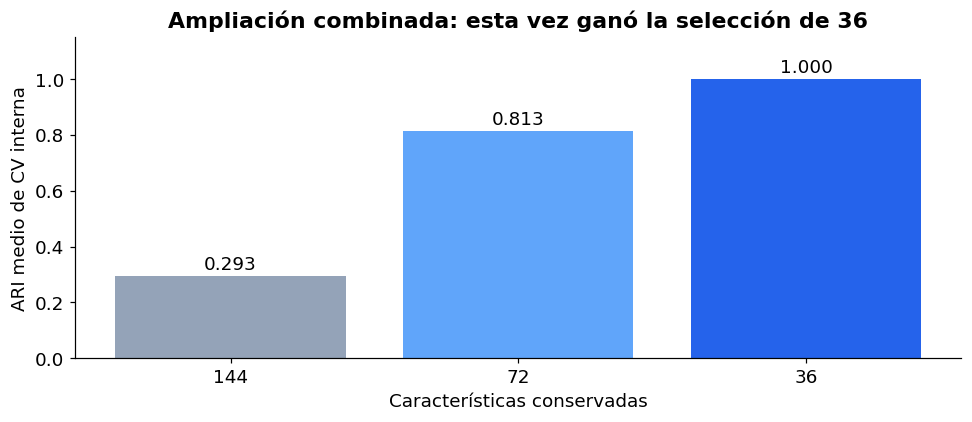

In [12]:
cv = pd.read_csv(DATOS / "huellas_comparacion_cv.csv")
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(cv["columnas"].astype(str), cv["ari_medio"], color=["#94A3B8", "#60A5FA", "#2563EB"])
for i, v in enumerate(cv["ari_medio"]): ax.text(i, v+0.025, f"{v:.3f}", ha="center")
ax.set(xlabel="Características conservadas", ylabel="ARI medio de CV interna", ylim=(0,1.15),
       title="Ampliación combinada: esta vez ganó la selección de 36")
plt.tight_layout(); plt.show()

## Qué cambió al agregar impresiones directas de Anguli

El modelo de 72 columnas rechazó las 75 autorizadas de Anguli incluidas en el diagnóstico y también rechazó las 50 intrusas. Esto mostraba una diferencia entre el tipo de entradas aprendido y el nuevo procedimiento de captura. No bastaba con informar que rechazaba intrusos: tampoco aceptaba las autorizadas.

La solución evaluada fue combinar 120 capturas anteriores con 60 autorizadas de Anguli para entrenamiento. Se repitió la comparación interna de 144/72/36. Esta vez ganó 36: ARI medio 1, frente a 0,813 con 72 y 0,293 con 144. Se recalcularon selección, escalas y centroides. El umbral se volvió a calibrar con validación.

No seguimos reduciendo columnas por costumbre. La decisión depende de los datos y de una comparación prefijada. Tampoco son 36 componentes PCA: son **36 columnas originales seleccionadas de las 144**.

Las impresiones corresponden a las mismas bases conocidas. Sus parámetros de ruido, rayaduras, traslación y rotación estaban en cero en el lote ensayado; aun así, no son copias exactas de las bases. No podemos atribuir todos los cambios a una única causa ni generalizar a cualquier configuración de Anguli.

grupo                   autorizado  intruso
particion     fuente                       
entrenamiento anguli            60        0
              anterior         120        0
validacion    anguli            15       50
              anterior          30       20

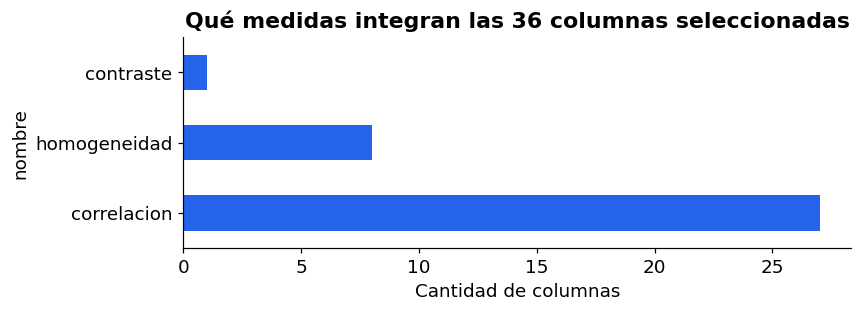

In [13]:
display(pd.crosstab([meta["particion"], meta["fuente"]], meta["grupo"]))
seleccionadas = pd.Series(paquete["nombres_seleccionados"], name="nombre")
medidas = seleccionadas.str.rsplit("_", n=1).str[-1].value_counts()
medidas.plot.barh(color="#2563EB", figsize=(8, 3))
plt.xlabel("Cantidad de columnas"); plt.title("Qué medidas integran las 36 columnas seleccionadas")
plt.tight_layout(); plt.show()

## Reconocer un grupo no alcanza para autorizar

K-means siempre encuentra el centroide más cercano, incluso para una intrusa. Por eso calculamos la distancia mínima y preguntamos si está suficientemente cerca:

$$\boxed{d_{min}\leq\tau\Rightarrow AUTORIZADO;\qquad d_{min}>\tau\Rightarrow NO\ AUTORIZADO.}$$

Aumentar el umbral facilita aceptación, pero puede permitir intrusos. Reducirlo puede rechazar autorizadas. Definimos FAR como intrusas aceptadas / intrusas evaluadas, y FRR como autorizadas rechazadas / autorizadas evaluadas.

Nuestra calibración minimiza $(FAR+FRR)/2$, con desempate por menor FAR y luego menor umbral. Es una política de desarrollo, no una ley universal de seguridad. Se prueban umbrales en los cambios posibles de decisión entre distancias ordenadas; no hace falta ensayar infinitos números.

El umbral actual es **4,136012625**. El anterior era 5,292172576, pero cambiaron el espacio y el escalado, por lo que no podemos concluir que el nuevo sea simplemente más estricto.

El umbral se eligió usando validación: sus métricas son de calibración, no de prueba independiente. En el combinado hubo 44/45 autorizadas aceptadas con identidad correcta y 70/70 intrusas rechazadas en esa validación.

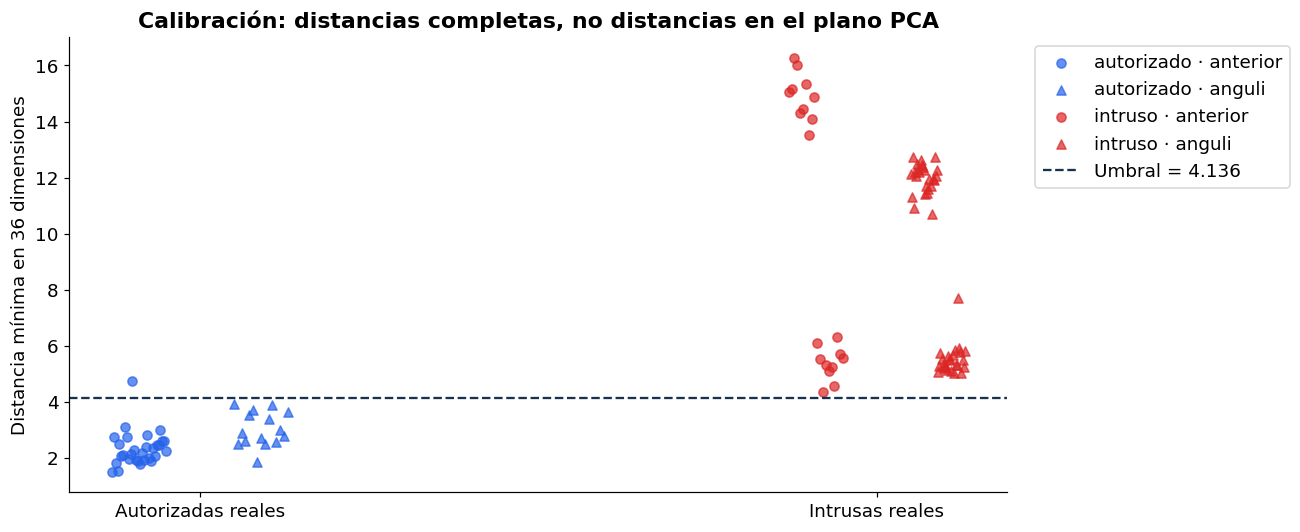

In [14]:
dmin = distancias.min(axis=1)
fig, ax = plt.subplots(figsize=(12, 5))
for i, (grupo, color) in enumerate([("autorizado", "#2563EB"), ("intruso", "#DC2626")]):
    for fuente, marcador, desplazamiento in [("anterior", "o", -0.09), ("anguli", "^", 0.09)]:
        m = val & meta["grupo"].eq(grupo).to_numpy() & meta["fuente"].eq(fuente).to_numpy()
        valores = dmin[m]
        ax.scatter(i+desplazamiento+np.linspace(-0.04,0.04,len(valores)), valores,
                   color=color, marker=marcador, alpha=0.7, label=f"{grupo} · {fuente}")
ax.axhline(tau, color="#16324F", ls="--", label=f"Umbral = {tau:.3f}")
ax.set_xticks([0,1], ["Autorizadas reales", "Intrusas reales"])
ax.set_ylabel("Distancia mínima en 36 dimensiones")
ax.set_title("Calibración: distancias completas, no distancias en el plano PCA")
ax.legend(bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout(); plt.show()

La autorizada por encima del umbral es un falso rechazo que se conserva. Un gráfico PCA no debe dibujar un círculo de aceptación como si reprodujera exactamente la regla en 36 dimensiones: las dimensiones descartadas también aportan distancia.

El siguiente plano añade las intrusas de validación únicamente mediante transformación. No ajustan PCA ni los centroides. Su posición ayuda a explicar el conjunto observado, pero no demuestra que cualquier intruso futuro quede separado.

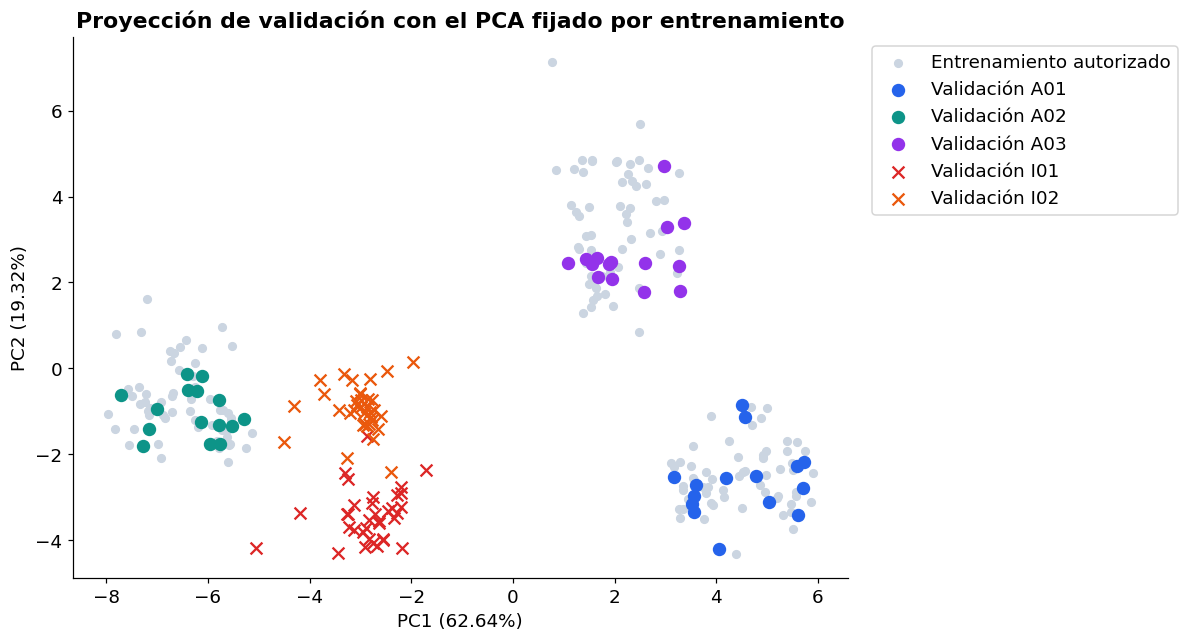

In [15]:
fig, ax = plt.subplots(figsize=(11,6))
ax.scatter(P[train,0], P[train,1], color="#CBD5E1", s=25, label="Entrenamiento autorizado")
for identidad in ["A01","A02","A03","I01","I02"]:
    m = val & meta["identidad"].eq(identidad).to_numpy()
    ax.scatter(P[m,0], P[m,1], c=COLORES[identidad], marker="x" if identidad.startswith("I") else "o",
               s=60, label=f"Validación {identidad}")
ax.set(xlabel=f"PC1 ({fracciones[0]:.2%})", ylabel=f"PC2 ({fracciones[1]:.2%})",
       title="Proyección de validación con el PCA fijado por entrenamiento")
ax.legend(bbox_to_anchor=(1.02,1), loc="upper left"); plt.tight_layout(); plt.show()

## Qué mostró el control apartado y qué no mostró

Después de fijar el modelo se consultaron 25 impresiones Anguli apartadas: 15 autorizadas y 10 intrusas. Se aceptaron e identificaron 14/15 autorizadas y se rechazaron 10/10 intrusas. A03/Impression_26 tuvo distancia aproximada 6,5053 y fue rechazada. No se aumentó el umbral para ocultar ese fallo.

Ese control se reprodujo en Windows con decisiones y distancias coincidentes. Son las mismas imágenes, no 50 observaciones independientes. Tampoco incluye nuevos dedos intrusos: comparte bases con el desarrollo. La prueba final original permanece reservada y por sí sola no evaluará todas las configuraciones futuras de Anguli.

In [16]:
control = pd.read_csv(DATOS / "control_anguli.csv")
resumen = control.groupby("identidad_real").agg(consultas=("aceptada","size"),
                                                 aceptadas=("aceptada","sum"))
resumen["rechazadas"] = resumen["consultas"] - resumen["aceptadas"]
display(resumen)

,consultas,aceptadas,rechazadas
identidad_real,,,
A01,5,5,0
A02,5,5,0
A03,5,4,1
I01,5,0,5
I02,5,0,5


## Recorrido de una huella nueva

La imagen se normaliza una vez; se extraen 144 números; se toman las 36 posiciones guardadas; se aplican medias y escalas guardadas; se calculan tres distancias; se compara la mínima con el umbral. Solo si se acepta puede mostrarse la identidad asociada al grupo.

El PCA no participa en esa decisión. Las celdas de este cuaderno únicamente lo ajustan para mostrar el modelo actual. No modifican ningún archivo de modelos del proyecto. La lista de selección no se recalcula para cada consulta y los centroides no se desplazan cuando llega una imagen nueva.

**Para explicar al profesor:** los gráficos permiten entender la estructura; ARI permite contrastar los grupos con identidades; FAR y FRR describen rechazo y aceptación. Son aspectos relacionados, pero ninguno sustituye a los otros.

## Fuentes y alcance de esta guía

Texto didáctico basado en la consigna **Trabajo Final 2026**, la presentación **Clase 9 — Aprendizaje 2026** del material de cátedra y los archivos del proyecto que se enlazan debajo. El detalle del descriptor acústico sigue la implementación y su documentación, que remite a Clase 10 — Percepción; esa presentación no estaba incluida en el ZIP consultado. Los ejemplos hipotéticos se identifican como tales.

Versión del repositorio consultada: `eb97d38ab95d1f3a776734b2b2fa36ed54df37b9`, 24/10/2026. Las cifras describen esa versión, no garantizan otras condiciones.

- [documentos/etapas/mejora_huellas_v1.md](https://github.com/peterortiz03/Trabajo-Final-IA1/blob/eb97d38ab95d1f3a776734b2b2fa36ed54df37b9/documentos/etapas/mejora_huellas_v1.md)
- [documentos/etapas/cierre_etapa06.md](https://github.com/peterortiz03/Trabajo-Final-IA1/blob/eb97d38ab95d1f3a776734b2b2fa36ed54df37b9/documentos/etapas/cierre_etapa06.md)
- [documentos/guias/modelo_combinado_anguli_v1.md](https://github.com/peterortiz03/Trabajo-Final-IA1/blob/eb97d38ab95d1f3a776734b2b2fa36ed54df37b9/documentos/guias/modelo_combinado_anguli_v1.md)
- [config/aplicacion.json](https://github.com/peterortiz03/Trabajo-Final-IA1/blob/eb97d38ab95d1f3a776734b2b2fa36ed54df37b9/config/aplicacion.json)
- [documentos/evidencias/08_huellas_combinadas/comparacion_cv.csv](https://github.com/peterortiz03/Trabajo-Final-IA1/blob/eb97d38ab95d1f3a776734b2b2fa36ed54df37b9/documentos/evidencias/08_huellas_combinadas/comparacion_cv.csv)